The baseline gets macro-F1 0.541. It does not look at the post text and knows the author only through the level and its spread. I add features step by step and keep a step if it improves 5-fold cross-validation over train authors.

Steps:

1. LightGBM regression of the residual instead of classification, then two thresholds tuned for macro-F1
2. author dynamics: how recent posts did compared to the level
3. post fields that the baseline does not use: reshare, images, tagged companies
4. history of earlier posts of the same kind
5. text: TF-IDF and Qwen3-Embedding-0.6B, each turned into one out-of-fold prediction of the residual
6. kNN over the author's earlier posts

In [1]:
import json
import sys

import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold

sys.path.insert(0, "..")
from kairos import features
from kairos.data import DATA_DIR, load_followers, load_labels, load_posts, load_split
from kairos.label import author_level
from kairos.metrics import score

In [2]:
posts = features.build(author_level(load_posts()), load_followers())
posts = posts.merge(load_labels()[["author", "post", "split", "label"]], on=["author", "post"], how="left")
fields = []
for f in (DATA_DIR / "posts").glob("AUTHOR_*.json"):
    feed = json.loads(f.read_text(encoding="utf-8"))
    for p in feed["posts"]:
        fields.append(
            {
                "author": feed["author"],
                "post": p["urn"],
                "crawled": feed["crawledAt"],
                "reshare": "resharedPost" in p,
                "n_images": len(p.get("images") or []),
                "n_companies": len(p.get("companyMentions") or []),
                "doc_pages": (p.get("document") or {}).get("totalPageCount") or 0,
            }
        )
posts = posts.merge(pd.DataFrame(fields), on=["author", "post"], how="left")
posts["age_days"] = (
    pd.to_datetime(posts.crawled, format="ISO8601", utc=True) - posts.posted_at
).dt.total_seconds() / 86400
cut = load_split()["cutoffs_on_log_residual"]
tr, te = (posts.split == "train").to_numpy(), (posts.split == "test").to_numpy()
y, label = posts.resid.to_numpy(), posts.label.fillna(-1).astype(int).to_numpy()
print(f"{len(posts):,} own posts, train {tr.sum():,}, test {te.sum():,} labelled")
posts[tr].groupby("reshare").agg(
    posts=("label", "size"),
    mean_resid=("resid", "mean"),
    above=("label", lambda s: (s == 2).mean()),
    below=("label", lambda s: (s == 0).mean()),
)

112,852 own posts, train 71,395, test 17,623 labelled


,posts,mean_resid,above,below
reshare,,,,
False,42312,0.590831,0.266449,0.128805
True,29083,-0.048473,0.103291,0.301723


Reshares (with or without a comment) are 41% of train posts and do much worse than original posts. The level mixes both, so an author who reshares a lot has a low level, and their original posts beat it.

## Author dynamics and same-kind history

The level is the median over the whole past of the author. If the audience grows, new posts beat this median, if it shrinks they fall below it, so recent posts add information. The same is computed separately for reshares and original posts. All features use only earlier posts, like the level.

In [3]:
def past(col, f, keys="author"):
    return posts.groupby(keys)[col].transform(lambda s: f(s.shift(1)))


lr, kind = "log_reactions", ["author", "reshare"]
posts["last1"] = past(lr, lambda s: s) - posts.level
posts["mean3"] = past(lr, lambda s: s.rolling(3, 1).mean()) - posts.level
posts["mean10"] = past(lr, lambda s: s.rolling(10, 1).mean()) - posts.level
posts["ewm"] = past(lr, lambda s: s.ewm(halflife=5).mean()) - posts.level
posts["max10"] = past(lr, lambda s: s.rolling(10, 1).max()) - posts.level
posts["resid_mean"] = past("resid", lambda s: s.expanding().mean())
posts["share_above"] = past("resid", lambda s: (s > cut["high"]).where(s.notna()).expanding().mean())
posts["share_below"] = past("resid", lambda s: (s < cut["low"]).where(s.notna()).expanding().mean())
posts["posts_30d"] = posts.groupby("author").posted_at.transform(
    lambda s: np.arange(len(s)) - s.searchsorted(s - pd.Timedelta(days=30))
)
posts["reshare_share"] = past("reshare", lambda s: s.astype(float).expanding().mean())
posts["kind_level"] = past(lr, lambda s: s.expanding().median(), kind) - posts.level
posts["kind_last1"] = past(lr, lambda s: s, kind) - posts.level
posts["kind_mean3"] = past(lr, lambda s: s.rolling(3, 1).mean(), kind) - posts.level
posts["kind_n"] = posts.groupby(kind).cumcount()
posts["type_level"] = past(lr, lambda s: s.expanding().median(), ["author", "content_type"]) - posts.level
DYN = ["last1", "mean3", "mean10", "ewm", "max10", "resid_mean", "share_above", "share_below", "posts_30d"]
FIELDS = ["reshare", "n_images", "n_companies", "doc_pages"]
KIND = ["reshare_share", "kind_level", "kind_last1", "kind_mean3", "kind_n", "type_level"]

In [4]:
folds = list(GroupKFold(5).split(np.flatnonzero(tr), groups=posts.author[tr]))


def oof(X, model):
    take = X.iloc if isinstance(X, pd.DataFrame) else X
    out, idx = np.full(len(posts), np.nan), np.flatnonzero(tr)
    for a, b in folds:
        out[idx[b]] = model.fit(take[idx[a]], y[idx[a]]).predict(take[idx[b]])
    out[te] = model.fit(take[idx], y[idx]).predict(take[np.flatnonzero(te)])
    return out

## Text features



In [5]:
tfidf = TfidfVectorizer(min_df=3, max_features=300_000, ngram_range=(1, 2), sublinear_tf=True).fit_transform(posts.text)
posts["r_tfidf"] = oof(tfidf, Ridge(alpha=3.0))

In [6]:
emb_file = DATA_DIR.parent / "results" / "cache" / "qwen3_emb.npz"
if emb_file.exists():
    cached = np.load(emb_file)
    assert (cached["post"] == posts.post.to_numpy()).all()
    emb = cached["emb"].astype(np.float32)
else:
    from sentence_transformers import SentenceTransformer

    st = SentenceTransformer("Qwen/Qwen3-Embedding-0.6B", model_kwargs={"torch_dtype": "float16"})
    st.max_seq_length = 512
    emb = st.encode(posts.text.tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=True)
    emb_file.parent.mkdir(parents=True, exist_ok=True)
    np.savez(emb_file, emb=emb.astype(np.float16), post=posts.post.to_numpy().astype(str))
posts["r_emb"] = oof(emb, Ridge(alpha=10.0))
TEXT = ["r_tfidf", "r_emb"]

## kNN over the author's earlier posts

Different authors get reactions for different things, for example job news or tutorials. For each post I take the 5 most similar earlier posts of the same author (cosine similarity of embeddings) and compare their reactions with the current level. The max similarity shows whether the topic repeats.

In [7]:
knn_resid, knn_sim = np.full(len(posts), np.nan), np.full(len(posts), np.nan)
logr, level = posts[lr].to_numpy(), posts.level.to_numpy()
for rows in posts.groupby("author").indices.values():
    sim = emb[rows] @ emb[rows].T
    for i in range(1, len(rows)):
        top = np.argsort(-sim[i, :i])[:5]
        knn_resid[rows[i]] = logr[rows[top]].mean() - level[rows[i]]
        knn_sim[rows[i]] = sim[i, top[0]]
posts["knn_resid"], posts["knn_sim"] = knn_resid, knn_sim
KNN = ["knn_resid", "knn_sim"]

## LightGBM and thresholds

The label is the residual cut at two points, so I regress the residual directly, it has more information than three classes. Two thresholds are chosen on the out-of-fold train predictions to maximize macro-F1. CV is computed on the same predictions the thresholds were tuned on, so it is slightly optimistic (about +0.001, checked by splitting train in half). Test scores don't have this problem.

In [8]:
BASE = features.CONTENT_NUM + features.HISTORY_NUM + features.ARTEFACT_NUM + features.CONTENT_CAT
posts["content_type"] = posts.content_type.astype("category")
PARAMS = {
    "objective": "huber",
    "learning_rate": 0.03,
    "n_estimators": 800,
    "num_leaves": 63,
    "min_child_samples": 40,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.7,
    "random_state": 42,
    "verbose": -1,
}


def macro_f1(truth, pred):
    cm = np.bincount(truth * 3 + pred, minlength=9).reshape(3, 3)
    return np.mean(2 * np.diag(cm) / (cm.sum(0) + cm.sum(1)))


def fit_thresholds(pred, truth):
    qs = np.quantile(pred, np.linspace(0.02, 0.98, 97))
    return max(
        ((lo, hi) for i, lo in enumerate(qs) for hi in qs[i + 1 :]), key=lambda c: macro_f1(truth, np.digitize(pred, c))
    )


def run(cols):
    model = lgb.LGBMRegressor(**PARAMS)
    pred = oof(posts[cols], model)
    classes = np.digitize(pred, fit_thresholds(pred[tr], label[tr]))
    return model, classes, {"cv_macro_f1": score(label[tr], classes[tr])["macro_f1"], **score(label[te], classes[te])}


SETS = {
    "baseline features": BASE,
    "+ author dynamics": BASE + DYN,
    "+ post fields": BASE + DYN + FIELDS,
    "+ same-kind history": BASE + DYN + FIELDS + KIND,
    "+ text (TF-IDF, embeddings)": BASE + DYN + FIELDS + KIND + TEXT,
    "+ kNN over own posts": BASE + DYN + FIELDS + KIND + TEXT + KNN,
}
results = {name: run(cols) for name, cols in SETS.items()}
pd.DataFrame({name: r[2] for name, r in results.items()}).T

,cv_macro_f1,macro_f1,qwk,accuracy
baseline features,0.5938,0.5865,0.4940,0.6443
+ author dynamics,0.6134,0.6044,0.5258,0.6530
+ post fields,0.6213,0.6101,0.5314,0.6613
+ same-kind history,0.6376,0.6251,0.5513,0.6752
"+ text (TF-IDF, embeddings)",0.6583,0.6464,0.5836,0.6843
+ kNN over own posts,0.6602,0.6464,0.5836,0.6897


## Feature importance

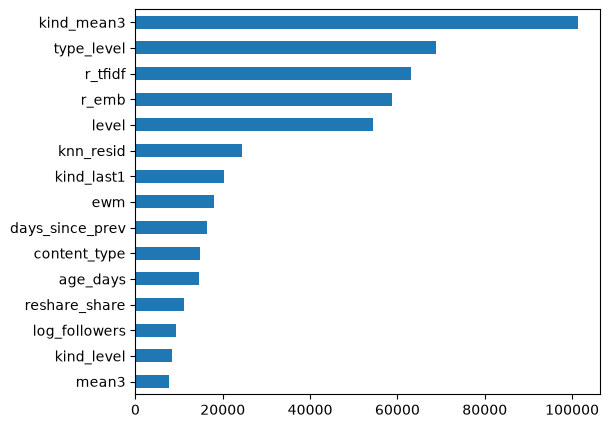

In [9]:
model, classes, _ = results["+ kNN over own posts"]
pd.Series(model.booster_.feature_importance("gain"), model.feature_name_).sort_values()[-15:].plot.barh(figsize=(6, 5));

In [ ]:
posts.loc[te, ["author", "post"]].assign(label=classes[te]).to_csv("predictions.csv", index=False)

test: 17,623 posts
  macro-F1  0.6464   (primary)
  QWK       0.5836
  accuracy  0.6897
  F1 by class  below 0.5304  typical 0.7503  above 0.6584
  confusion, rows = truth below / typical / above:
      1,840   1,681      20
      1,512   8,121     858
         45   1,353   2,193
